Dimensões do dataset: 7139 janelas x 20 colunas
Total de valores nulos: 0
Janelas duplicadas: 0

Distribuição dos Comportamentos (Vaca T01):
          Janelas (10s)  Tempo Total (min)  Proporção (%)
behavior                                                 
7                  4468              744.7          62.59
2                  1627              271.2          22.79
3                  1044              174.0          14.62


Text(0, 0.5, 'Comportamento')

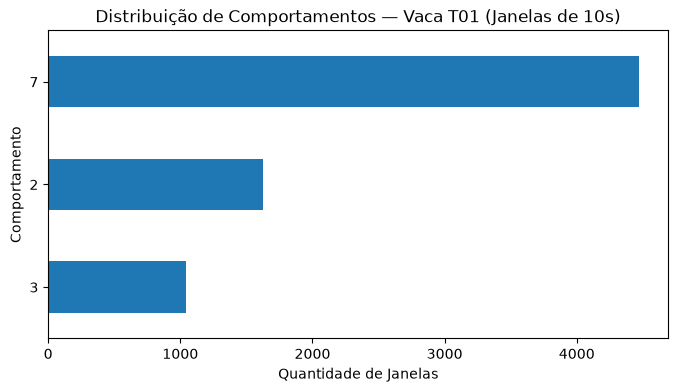

In [11]:
# Inspeção de formato, nulos, duplicatas e distribuição dos comportamentos da vaca T01
import os
import matplotlib.pyplot as plt
import pandas as pd

# 1. Carregar o arquivo limpo da vaca T01
caminho_t01 = os.path.join("./dados/clean", "T01.csv")
df_t01 = pd.read_csv(caminho_t01)

# 2. Auditar formato, nulos e janelas duplicadas
print(f"Dimensões do dataset: {df_t01.shape[0]} janelas x {df_t01.shape[1]} colunas")
print(f"Total de valores nulos: {df_t01.isnull().sum().sum()}")
print(f"Janelas duplicadas: {df_t01['janela'].duplicated().sum()}")

# 3. Montar a tabela com contagem, tempo total e percentual de cada comportamento
contagem = df_t01["behavior"].value_counts()
percentual = (df_t01["behavior"].value_counts(normalize=True) * 100).round(2)

resumo_classes = pd.DataFrame(
    {
        "Janelas (10s)": contagem,
        "Tempo Total (min)": (contagem * 10 / 60).round(1),
        "Proporção (%)": percentual,
    }
)
print("\nDistribuição dos Comportamentos (Vaca T01):")
print(resumo_classes)

# 4. Plotar o gráfico de barras horizontal da distribuição
plt.figure(figsize=(8, 4))
contagem.sort_values().plot(kind="barh")
plt.title("Distribuição de Comportamentos — Vaca T01 (Janelas de 10s)")
plt.xlabel("Quantidade de Janelas")
plt.ylabel("Comportamento")


In [ ]:
# Análise exploratória das 10 vacas (T01 a T10), com janelas de 10 s e 3 classes: deitada, em pé/andando e alimentação
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from pathlib import Path

# 1. Escolher o estilo dos gráficos e criar a pasta onde as figuras serão salvas
sns.set_theme(style="whitegrid")
Path("figuras").mkdir(exist_ok=True)

# 2. Definir o nome e a cor de cada comportamento (a mesma cor em todos os gráficos)
nomes = {7: "Deitada", 2: "Em pé/andando", 3: "Alimentação"}
ordem = ["Deitada", "Em pé/andando", "Alimentação"]
cores = {"Deitada": "#2a78d6", "Em pé/andando": "#eb6834", "Alimentação": "#1baf7a"}
lista_cores = [cores[nome] for nome in ordem]

# 3. Carregar e juntar os CSVs limpos de todas as vacas
files = sorted(Path("./dados/clean").glob("*.csv"))
df = pd.concat((pd.read_csv(f) for f in files), ignore_index=True)

# 4. Converter o comportamento para inteiro e criar a coluna com o nome dele
df["behavior"] = df["behavior"].astype(int)
df["comportamento"] = df["behavior"].map(nomes)

# 5. Converter o timestamp para a hora local do curral (CDT = UTC-5)
data_hora = pd.to_datetime(df["timestamp"], unit="s") - pd.Timedelta(hours=5)
df["hora"] = data_hora.dt.hour
df["hora_decimal"] = data_hora.dt.hour + data_hora.dt.minute / 60

print(f"{len(df)} janelas de 10 s | {df['vaca_id'].nunique()} vacas")

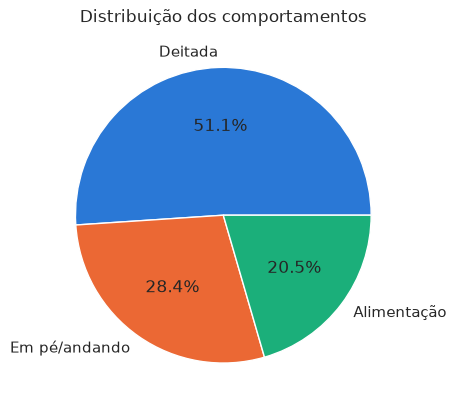

comportamento
Deitada          36375
Em pé/andando    20258
Alimentação      14611
Name: count, dtype: int64


In [3]:
# Distribuição dos comportamentos: sempre prever "deitada" acerta cerca de 51%, o chute que o modelo precisa superar
# 1. Plotar o gráfico de pizza com a proporção de cada comportamento
contagem_classes = df["comportamento"].value_counts()[ordem]
plt.pie(contagem_classes, labels=ordem, colors=lista_cores, autopct="%.1f%%")
plt.title("Distribuição dos comportamentos")
plt.savefig("figuras/01_distribuicao_classes.png", bbox_inches="tight")
plt.show()

# 2. Mostrar a contagem de cada comportamento
print(contagem_classes)

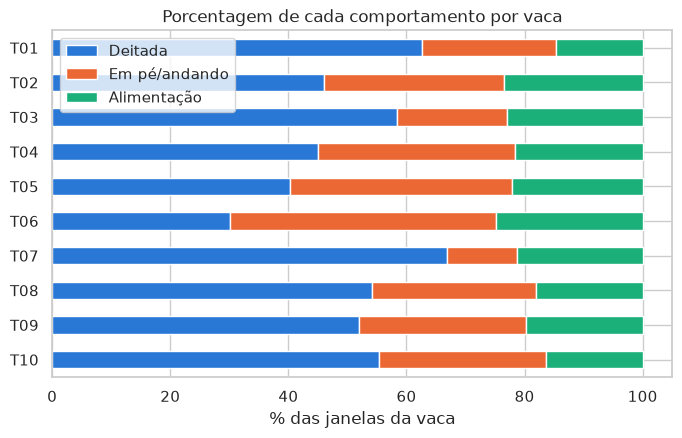

In [4]:
# Comportamento por vaca: as proporções variam bastante, então o teste deve usar vacas não vistas no treino
# 1. Calcular, para cada vaca, a porcentagem de tempo em cada comportamento
por_vaca = pd.crosstab(df["vaca_id"], df["comportamento"], normalize="index") * 100
por_vaca = por_vaca[ordem]

# 2. Plotar barras empilhadas (cada barra soma 100%)
por_vaca.plot(kind="barh", stacked=True, color=lista_cores, figsize=(8, 4.5))
plt.gca().invert_yaxis()
plt.title("Porcentagem de cada comportamento por vaca")
plt.xlabel("% das janelas da vaca")
plt.ylabel("")
plt.legend()
plt.savefig("figuras/02_comportamento_por_vaca.png", bbox_inches="tight")
plt.show()

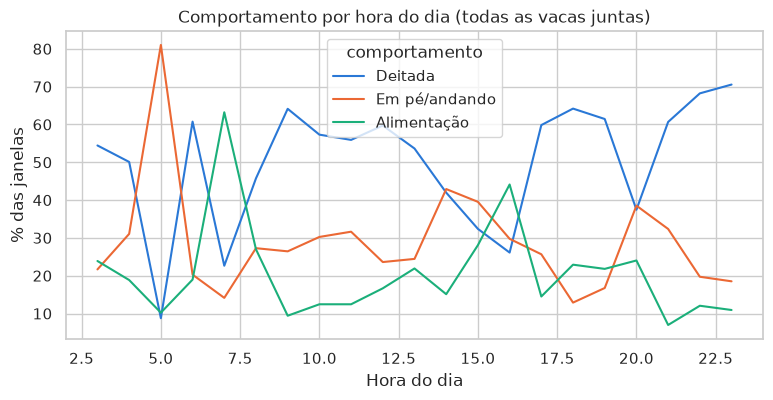

In [5]:
# Comportamento por hora: mais deitada à noite e no começo da tarde, e o pico de em pé/andando às 5h vem após um período sem dados
# 1. Calcular, para cada hora do dia, a porcentagem de cada comportamento
por_hora = pd.crosstab(df["hora"], df["comportamento"], normalize="index") * 100
por_hora = por_hora[ordem]

# 2. Remover a primeira hora, que tem poucas janelas (a coleta começa às 02:57)
por_hora = por_hora.iloc[1:]

# 3. Plotar uma linha para cada comportamento
por_hora.plot(kind="line", color=lista_cores, figsize=(9, 4))
plt.title("Comportamento por hora do dia (todas as vacas juntas)")
plt.xlabel("Hora do dia")
plt.ylabel("% das janelas")
plt.savefig("figuras/03_comportamento_por_hora.png", bbox_inches="tight")
plt.show()

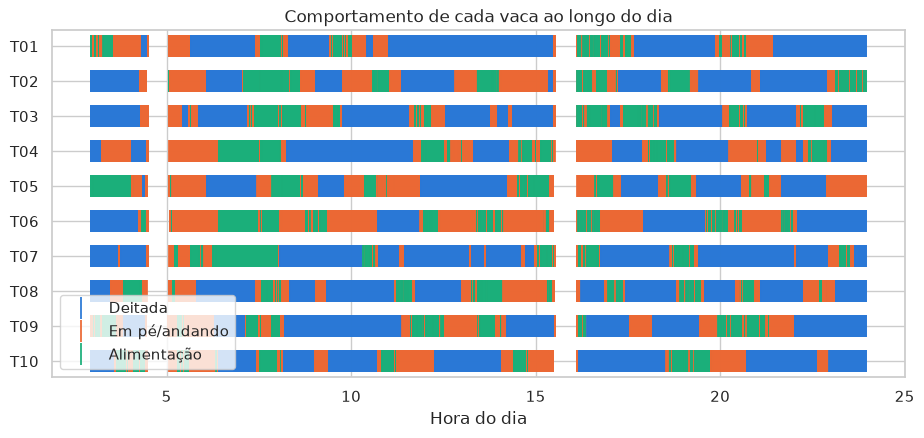

In [7]:
# Linha do tempo por vaca: os blocos contínuos justificam usar janelas vizinhas, e as lacunas simultâneas provavelmente são saídas do curral
# 1. Plotar um traço vertical para cada janela de 10 s (linha = vaca, eixo x = hora)
plt.figure(figsize=(11, 4.5))
sns.scatterplot(
    data=df, x="hora_decimal", y="vaca_id", hue="comportamento", hue_order=ordem,
    palette=cores, marker="|", s=250,
)
plt.title("Comportamento de cada vaca ao longo do dia")
plt.xlabel("Hora do dia")
plt.ylabel("")
plt.legend()
plt.savefig("figuras/04_linha_do_tempo_vacas.png", bbox_inches="tight")
plt.show()